# Cross-Detector Ensemble vs RF-DETR-M Ensemble (RF12), Common Protocol
The cross-detector ensemble combines four single models (YOLO11n Y5, RT-DETR-L R6, YOLO26l, RF-DETR-M RF7). RF12 (WBF of RF7, RF10 and RF11) is evaluated separately as the reference.

## Section 1: Install

In [1]:
!pip install -q -U ultralytics supervision scikit-learn ensemble-boxes


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Section 2: Imports

In [2]:
import time
import pickle
import shutil
from itertools import combinations
from pathlib import Path

import cv2
import yaml
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import supervision as sv
from IPython.display import display
from PIL import Image, ImageOps
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from supervision.metrics import MeanAveragePrecision
from ensemble_boxes import weighted_boxes_fusion
from ultralytics import YOLO, RTDETR
from rfdetr import from_checkpoint

GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'
print('GPU:', GPU)

C:\Users\zheng\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GPU: NVIDIA GeForce RTX 3070


## Section 3: Paths, Detectors and Dataset

In [3]:
PROJECT_ROOT = Path.cwd().resolve().parents[1]  # ai-applications/vs_notebooks -> repo root
DATASET_DIR = PROJECT_ROOT / 'data' / 'wildlife_dataset'
DATA = DATASET_DIR / 'wildlife_dataset.yaml'
TRAINED = PROJECT_ROOT / 'ai-applications' / 'trained_models'
UL_WEIGHTS = Path('YOLO_RTDETR_All_Runs_Evaluation') / 'weights'  # weights downloaded by the all-runs evaluation notebook
RESULTS_DIR = Path('cross_detector_ensemble_common'); RESULTS_DIR.mkdir(exist_ok=True)

DETECTORS = {
    'YOLO11n':   ('yolo',   UL_WEIGHTS / 'yolo11nflip50rot0p0mosaic0.pt'),     # Y5 (best YOLO11n run)
    'RT-DETR-L': ('rtdetr', UL_WEIGHTS / 'rtdetr-lflip50rot0p0mosaic100.pt'),  # R6 (best RT-DETR-L run)
    'YOLO26l':   ('yolo',   UL_WEIGHTS / 'yolo26l.pt'),
    'RF7':       ('rf',     TRAINED / 'rfdetr_erasing_10.pth'),                # RF-DETR-M, random erasing 10%
}
REFERENCE = ('RF12', 'rf12', [TRAINED / 'rfdetr_erasing_10.pth', TRAINED / 'rfdetr_dropout_10.pth', TRAINED / 'rfdetr_dropout_20.pth'])
for name, (_, p) in list(DETECTORS.items()) + [(REFERENCE[0], REFERENCE[1:])]:
    for q in (p if isinstance(p, list) else [p]):
        assert q.exists(), f'{name}: missing {q}'
MODEL_NAMES = list(DETECTORS)          # members of the cross-detector ensemble
ALL_NAMES = MODEL_NAMES + ['RF12']     # + reference

names = yaml.safe_load(open(DATA))['names']
CLASS_NAMES = [names[i] for i in sorted(names)] if isinstance(names, dict) else list(names)
NC = len(CLASS_NAMES)

# Same dataset loading as the RF-DETR and all-runs notebooks
SPLITS = ['val', 'test']
datasets = {s: sv.DetectionDataset.from_yolo(images_directory_path=str(DATASET_DIR / 'images' / s),
                                             annotations_directory_path=str(DATASET_DIR / 'labels' / s),
                                             data_yaml_path=str(DATA)) for s in SPLITS}
PATHS = {s: list(datasets[s].image_paths) for s in SPLITS}
TARGETS = {s: [ann for _, _, ann in datasets[s]] for s in SPLITS}
for s in SPLITS:
    print(s, len(PATHS[s]), 'images,', sum(len(t) for t in TARGETS[s]), 'animals')
print(CLASS_NAMES)

val 332 images, 457 animals
test 331 images, 474 animals
['buffalo', 'elephant', 'rhino', 'zebra', 'okapi', 'leopard', 'cheetah']


## Section 4: Settings (same protocol as all other evaluations)

In [4]:
PREDICT_CONF = 0.01   # lowest confidence saved from every model
CONFS = [0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60, 0.70, 0.80, 0.90]  # threshold sweep
RECALL_BAND = 2.0     # final t: highest t whose validation recall is within 2 points of recall at t = 0.25
MATCH_IOU = 0.5       # IoU for a correct detection
TIE = 0.005           # mAP50-95 difference treated as a tie (broken by operational accuracy)
NMS_IOU = 0.70        # per-view, per-class NMS inside the ensemble
TTA_IOU = 0.55        # WBF IoU for merging the original and flipped view
CLUSTER_IOU = 0.55    # boxes from different detectors with IoU >= this are one animal
RF_WBF_IOU, RF_SKIP = 0.55, 0.1  # RF12 settings (trained_models/rfdetr_ensemble_wbf.json)
SEED = 42

## Section 5: Load Detectors

In [5]:
def valid(b, s, c):
    k = (c >= 0) & (c < NC)  # RF-DETR can output an unused class index at very low confidence
    return b[k], s[k], c[k]

def rf12_fuse(dets):
    """RF12: weighted boxes fusion of the three RF-DETR-M runs (same rule as RFDETR_ensemble_wbf.ipynb, equal weights)."""
    w = np.ones(len(dets))
    xyxy, conf, cls, mid = [], [], [], []
    for m, (b, s, c) in enumerate(dets):
        k = s >= RF_SKIP
        xyxy.append(b[k]); conf.append(s[k]); cls.append(c[k]); mid.append(np.full(k.sum(), m))
    xyxy, conf, cls, mid = map(np.concatenate, (xyxy, conf, cls, mid))
    bw = conf * w[mid]
    fb, fc, fl = [], [], []
    for c in np.unique(cls):
        order = np.flatnonzero(cls == c); order = order[np.argsort(-conf[order], kind='stable')]
        clusters, boxes = [], np.empty((0, 4))
        for i in order:
            if len(boxes):
                iou = sv.box_iou_batch(xyxy[i][None], boxes)[0]; j = iou.argmax()
                if iou[j] > RF_WBF_IOU:
                    clusters[j].append(i); mem = clusters[j]
                    boxes[j] = (bw[mem, None] * xyxy[mem]).sum(0) / bw[mem].sum(); continue
            clusters.append([i]); boxes = np.vstack([boxes, xyxy[i]])
        for mem, box in zip(clusters, boxes):
            best = np.zeros(len(w)); np.maximum.at(best, mid[mem], conf[mem])
            fb.append(box); fc.append((w * best).sum() / w.sum()); fl.append(int(c))
    if not fb:
        return np.zeros((0, 4)), np.zeros(0), np.zeros(0, int)
    return np.array(fb, float), np.array(fc, float), np.array(fl, int)

def unflip(xyxy, width):
    out = xyxy.copy(); out[:, 0], out[:, 2] = width - xyxy[:, 2], width - xyxy[:, 0]; return out

class Detector:
    def __init__(self, kind, path):
        self.kind = kind
        if kind == 'yolo': self.model = YOLO(str(path))
        elif kind == 'rtdetr': self.model = RTDETR(str(path))
        elif kind == 'rf': self.model = from_checkpoint(str(path))
        else: self.model = [from_checkpoint(str(p)) for p in path]

    def predict(self, path, flip=False):
        """Boxes (in original-image coordinates), confidences and classes, kept down to PREDICT_CONF."""
        if self.kind in ('rf', 'rf12'):  # as in RFDETR_ensemble_wbf.ipynb: PIL image, mirrored with ImageOps
            img = Image.open(path).convert('RGB'); width = img.width
            if flip: img = ImageOps.mirror(img)
        if self.kind == 'rf':
            d = self.model.predict(img, threshold=PREDICT_CONF)
            b, s, c = valid(d.xyxy.astype(float), d.confidence.astype(float), d.class_id.astype(int))
        elif self.kind == 'rf12':
            dets = []
            for m in self.model:
                d = m.predict(img, threshold=PREDICT_CONF)
                dets.append(valid(d.xyxy.astype(float), d.confidence.astype(float), d.class_id.astype(int)))
            b, s, c = rf12_fuse(dets)
        else:  # as in the all-runs notebook: Ultralytics predict, imgsz 640
            src = path
            if flip:
                src = cv2.flip(cv2.imread(path), 1)
            r = self.model.predict(src, imgsz=640, conf=PREDICT_CONF, verbose=False)[0]
            d = sv.Detections.from_ultralytics(r); width = r.orig_shape[1]
            b, s, c = valid(d.xyxy.astype(float), d.confidence.astype(float), d.class_id.astype(int))
        if flip:
            b = unflip(b, width)
        return b, s, c

detectors = {n: Detector(k, p) for n, (k, p) in DETECTORS.items()}
detectors['RF12'] = Detector(REFERENCE[1], REFERENCE[2])  # reference only, not an ensemble member
print('Loaded', ALL_NAMES)

C:\Users\zheng\AppData\Roaming\Python\Python314\site-packages\rfdetr\detr.py:639: FutureWarning: The `RFDETRBase` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
C:\Users\zheng\AppData\Roaming\Python\Python314\site-packages\rfdetr\detr.py:639: FutureWarning: The `RFDETRLargeDeprecated` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
C:\Users\zheng\AppData\Roaming\Python\Python314\site-packages\rfdetr\detr.py:639: FutureWarning: The `RFDETRSegPreview` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
[2026-10-28 20:31:59] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-28 20:31:59] [WARNING] rf-detr - Using patch size 16 instead of 

Loaded ['YOLO11n', 'RT-DETR-L', 'YOLO26l', 'RF7', 'RF12']


## Section 6: Predict Original and Flipped Images (cached)

In [6]:
def run_split(split):
    path = RESULTS_DIR / f'predictions_{split}.pkl'
    if path.exists():
        return pickle.load(open(path, 'rb'))
    recs = []
    for k, (p, t) in enumerate(zip(PATHS[split], TARGETS[split]), 1):
        r = {'image': p, 'gt': t.xyxy.astype(float), 'gcls': t.class_id.astype(int), 'A': {}, 'B': {}}
        for n, det in detectors.items():
            r['A'][n] = det.predict(p)
            if n in MODEL_NAMES:  # flipped view only needed for ensemble members (TTA)
                r['B'][n] = det.predict(p, flip=True)
        recs.append(r)
        if k % 50 == 0: print(f'{split}: {k} images')
    pickle.dump(recs, open(path, 'wb'))
    return recs

cache = {s: run_split(s) for s in SPLITS}
val, test = cache['val'], cache['test']

[2026-10-28 20:32:03] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).
[2026-10-28 20:32:03] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).
[2026-10-28 20:32:03] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).
[2026-10-28 20:32:03] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


val: 50 images
val: 100 images
val: 150 images
val: 200 images
val: 250 images
val: 300 images
test: 50 images
test: 100 images
test: 150 images
test: 200 images
test: 250 images
test: 300 images


## Section 7: Inference Time (RTX 3070)

In [7]:
# Same method for every detector: image path in, detections out (image loading included),
# 10 warm-up images, then the mean over all test images. TTA cost = time of the flipped view.
def time_detector(det, flip=False):
    for p in PATHS['test'][:10]:
        det.predict(p, flip)
    times = []
    for p in PATHS['test']:
        if torch.cuda.is_available(): torch.cuda.synchronize()
        t0 = time.perf_counter(); det.predict(p, flip)
        if torch.cuda.is_available(): torch.cuda.synchronize()
        times.append(1000 * (time.perf_counter() - t0))
    return float(np.mean(times))

MS_A = {n: time_detector(d) for n, d in detectors.items()}
MS_B = {n: time_detector(detectors[n], flip=True) for n in MODEL_NAMES}
ms_df = pd.DataFrame({'ms/image (original)': MS_A, 'ms/image (flipped view)': MS_B}); ms_df['GPU'] = GPU
ms_df.to_csv(RESULTS_DIR / 'inference_time.csv'); display(ms_df.round(1))

,ms/image (original),ms/image (flipped view),GPU
YOLO11n,11.5,11.6,NVIDIA GeForce RTX 3070
RT-DETR-L,29.7,30.2,NVIDIA GeForce RTX 3070
YOLO26l,16.3,16.9,NVIDIA GeForce RTX 3070
RF7,25.4,26.3,NVIDIA GeForce RTX 3070
RF12,69.6,NaN,NVIDIA GeForce RTX 3070


## Section 8: Common Evaluation Metrics

In [8]:
def to_sv(preds):
    return [sv.Detections(xyxy=b.reshape(-1, 4).astype(float), confidence=s.astype(float), class_id=c.astype(int)) for b, s, c in preds]

def counts_at(P, T, conf):
    # rows = true class, columns = predicted class, last row/column = background
    cm = sv.ConfusionMatrix.from_detections(predictions=P, targets=T, classes=CLASS_NAMES,
                                            conf_threshold=conf, iou_threshold=MATCH_IOU).matrix.astype(int)
    c = np.array([cm[i, i] for i in range(NC)])
    w = np.array([cm[:NC, i].sum() - cm[i, i] for i in range(NC)])  # predicted as this class, but another animal
    fp = np.array([cm[NC, i] for i in range(NC)])                     # predicted as this class, no animal
    m = np.array([cm[i, NC] for i in range(NC)])                      # animal of this class not detected
    return c, w, fp, m

def summary(c, w, fp, m):
    C, W, FP, M = c.sum(), w.sum(), fp.sum(), m.sum()
    p, r = C / max(C + W + FP, 1), C / max(C + W + M, 1)
    return {'Correct': int(C), 'Wrong': int(W), 'FP': int(FP), 'Missed': int(M), 'Precision': p, 'Recall': r,
            'F1': 2 * p * r / max(p + r, 1e-9), 'Op. acc.': p, 'Pure acc.': C / max(C + W, 1)}

def at_conf(P, T, conf, with_map=True):
    out = summary(*counts_at(P, T, conf))
    if with_map:
        m = MeanAveragePrecision().update([p[p.confidence >= conf] for p in P], T).compute()
        out.update({'mAP50': float(m.map50), 'mAP50-95': float(m.map50_95)})
    return out

def final_threshold(P, T):
    rec = np.array([at_conf(P, T, t, with_map=False)['Recall'] for t in CONFS]) * 100
    return float(np.array(CONFS)[rec >= rec[0] - RECALL_BAND].max())

def evaluate_val(preds):
    P = to_sv(preds); t = final_threshold(P, TARGETS['val'])
    return t, at_conf(P, TARGETS['val'], t)

## Section 9: Single Detectors (Common Protocol)

In [9]:
def filt(p, conf=PREDICT_CONF):
    b, s, c = p; k = s >= conf; return b[k], s[k], c[k]

single = {}
for n in ALL_NAMES:
    t, m = evaluate_val([filt(r['A'][n]) for r in val])
    single[n] = {'Final t': t, **m, 'ms/image': MS_A[n]}
single_df = pd.DataFrame(single).T
single_df.to_csv(RESULTS_DIR / 'single_detectors_val.csv')
display(single_df[['Final t', 'mAP50', 'mAP50-95', 'Precision', 'Recall', 'F1', 'Correct', 'Wrong', 'FP', 'Missed', 'ms/image']].round(4))

,Final t,mAP50,mAP50-95,Precision,Recall,F1,Correct,Wrong,FP,Missed,ms/image
YOLO11n,0.45,0.9116,0.7478,0.9417,0.9190,0.9302,420.0,3.0,23.0,34.0,11.5064
RT-DETR-L,0.60,0.9347,0.7727,0.9209,0.9431,0.9319,431.0,2.0,35.0,24.0,29.7001
YOLO26l,0.50,0.9330,0.7689,0.9618,0.9365,0.9490,428.0,1.0,16.0,28.0,16.3246
RF7,0.45,0.9539,0.8689,0.9541,0.9562,0.9552,437.0,2.0,19.0,18.0,25.4384
RF12,0.50,0.9573,0.8737,0.9648,0.9606,0.9627,439.0,1.0,15.0,17.0,69.6164


## Section 10: Per-View NMS and TTA Merge

In [10]:
def nms(p, iou_thr=NMS_IOU):
    b, s, c = p; o = np.argsort(-s); b, s, c = b[o], s[o], c[o]
    keep, removed = [], np.zeros(len(s), bool)
    for i in range(len(s)):
        if removed[i]: continue
        keep.append(i)
        rest = np.where((c == c[i]) & ~removed & (np.arange(len(s)) > i))[0]
        if len(rest):
            removed[rest[sv.box_iou_batch(b[i:i + 1], b[rest])[0] >= iou_thr]] = True
    keep = np.array(keep, int); return b[keep], s[keep], c[keep]

def merge_views(a, b, w, h):
    scale = np.array([w, h, w, h], float); boxes, scores, labels = [], [], []
    for xyxy, s, c in (a, b):
        nb_ = np.clip(xyxy / scale, 0, 1); k = (nb_[:, 2] > nb_[:, 0]) & (nb_[:, 3] > nb_[:, 1])
        boxes.append(nb_[k].tolist()); scores.append(s[k].tolist()); labels.append(c[k].tolist())
    if sum(len(s) for s in scores) == 0:
        return np.zeros((0, 4)), np.zeros(0), np.zeros(0, int)
    fb, fs, fl = weighted_boxes_fusion(boxes, scores, labels, iou_thr=TTA_IOU, skip_box_thr=PREDICT_CONF, conf_type='avg')
    return np.asarray(fb) * scale, np.asarray(fs), np.asarray(fl).astype(int)

SIZE = {p: Image.open(p).size for s_ in SPLITS for p in PATHS[s_]}  # (width, height)
VIEWS = {}
for split in ['val', 'test']:
    for n in MODEL_NAMES:
        VIEWS[n, 'off', split] = [nms(filt(r['A'][n])) for r in cache[split]]
        VIEWS[n, 'on', split] = [merge_views(nms(filt(r['A'][n])), nms(filt(r['B'][n])), *SIZE[r['image']]) for r in cache[split]]

tta = {}
for n in MODEL_NAMES:
    for mode in ['off', 'on']:
        tta[n, mode] = evaluate_val(VIEWS[n, mode, 'val'])[1]['mAP50-95']
TTA_AUTO = {n: 'on' if tta[n, 'on'] > tta[n, 'off'] else 'off' for n in MODEL_NAMES}
QUALITY = {n: single[n]['mAP50-95'] for n in MODEL_NAMES}  # vote weight and box priority
RANK = sorted(MODEL_NAMES, key=lambda n: -QUALITY[n])
display(pd.DataFrame({'without TTA': {n: tta[n, 'off'] for n in MODEL_NAMES}, 'with TTA': {n: tta[n, 'on'] for n in MODEL_NAMES}}).round(4))
print('TTA auto:', TTA_AUTO, '| ranking:', RANK)

,without TTA,with TTA
YOLO11n,0.7478,0.7512
RT-DETR-L,0.7729,0.6210
YOLO26l,0.7689,0.7791
RF7,0.8689,0.8197


TTA auto: {'YOLO11n': 'on', 'RT-DETR-L': 'off', 'YOLO26l': 'on', 'RF7': 'off'} | ranking: ['RF7', 'RT-DETR-L', 'YOLO26l', 'YOLO11n']


## Section 11: Grouping, Species Vote and Fusion

In [11]:
def iou1(a, b):
    return sv.box_iou_batch(a[None], b[None])[0, 0]

def fuse(per_model, members):
    items = sorted(((s, n, b, c) for n in members for b, s, c in zip(*per_model[n])), key=lambda t: -t[0])
    groups = []
    for s, n, b, c in items:
        best, best_iou = None, CLUSTER_IOU
        for g in groups:
            if n in g['m']: continue
            v = iou1(b, g['box'])
            if v >= best_iou: best, best_iou = g, v
        if best is None:
            groups.append({'m': {n: (s, b, c)}, 'box': b.copy()})
        else:
            best['m'][n] = (s, b, c)
            w = np.array([m[0] for m in best['m'].values()]); bx = np.array([m[1] for m in best['m'].values()])
            best['box'] = (w[:, None] * bx).sum(0) / w.sum()
    out = []
    for g in groups:
        votes = np.zeros(NC)
        for n, (s, _, c) in g['m'].items(): votes[c] += s * QUALITY[n]
        cls = int(votes.argmax()); top = next(n for n in RANK if n in g['m'])
        mb = np.array([m[1] for m in g['m'].values()]); confs = [g['m'].get(n, (0.0,))[0] for n in members]
        feats = confs + [len(g['m']) / len(members), np.mean([m[2] == cls for m in g['m'].values()]),
                         sv.box_iou_batch(mb, g['box'][None]).mean(), votes[cls] / max(votes.sum(), 1e-9), max(confs)] + list(np.eye(NC)[cls])
        out.append({'box_weighted': g['box'], 'box_best': g['m'][top][1], 'cls': cls, 'feats': np.array(feats, float),
                    'mean': float(sum(confs) / len(members)), 'max': float(max(confs))})
    return out

def build(members, tta_mode, split):
    mode = lambda n: tta_mode if tta_mode in ('on', 'off') else TTA_AUTO[n]
    t0 = time.perf_counter()
    groups = [fuse({n: VIEWS[n, mode(n), split][i] for n in members}, members) for i in range(len(cache[split]))]
    fuse_ms = 1000 * (time.perf_counter() - t0) / len(groups)
    # detectors run one after another: sum of their measured times (+ flipped view when TTA is on) + fusion time
    return groups, sum(MS_A[n] + (MS_B[n] if mode(n) == 'on' else 0) for n in members) + fuse_ms

def to_preds(groups, box, scores):
    return [(np.array([f[f'box_{box}'] for f in g]).reshape(-1, 4), np.asarray(sc, float), np.array([f['cls'] for f in g], int))
            for g, sc in zip(groups, scores)]

## Section 12: Stacking Layer

In [12]:
def match_labels(b, s, c, gt, gcls):
    iou = sv.box_iou_batch(b, gt) if len(b) and len(gt) else np.zeros((len(b), len(gt)))
    used = np.zeros(len(gt), bool); y = np.zeros(len(b), int)
    for i in np.argsort(-s):
        cand = np.where(~used)[0]
        if len(cand) and iou[i, cand].max() >= MATCH_IOU:
            j = cand[iou[i, cand].argmax()]; used[j] = True; y[i] = int(c[i] == gcls[j])
    return y

def labels_for(groups, records, box):
    y = []
    for g, r in zip(groups, records):
        if g:
            b = np.array([f[f'box_{box}'] for f in g]); c = np.array([f['cls'] for f in g]); s = np.array([f['mean'] for f in g])
            y += list(match_labels(b, s, c, r['gt'], r['gcls']))
    return np.array(y, int)

def unflatten(groups, flat):
    out, i = [], 0
    for g in groups: out.append(flat[i:i + len(g)]); i += len(g)
    return out

make_stacker = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

## Section 13: Configurations (206)

In [13]:
configs = []
for k in range(1, len(MODEL_NAMES) + 1):
    for members in combinations(MODEL_NAMES, k):
        for t_ in (['off', 'on'] if k == 1 else ['off', 'on', 'auto']):
            if k == 1: configs.append((members, t_, 'best', 'max'))
            else:
                for box in ['weighted', 'best']:
                    for score in ['mean', 'max', 'stacking']:
                        configs.append((members, t_, box, score))
print(len(configs), 'configurations')
built = {}
def get_groups(members, t_, split):
    if (members, t_, split) not in built: built[members, t_, split] = build(list(members), t_, split)
    return built[members, t_, split]

206 configurations


## Section 14: Configuration Search on Validation

In [14]:
rows, cv = [], StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for i, (members, t_, box, score) in enumerate(configs, 1):
    if len(members) == 1 and t_ == 'off':   # single detector exactly as deployed alone
        n = members[0]; preds = [filt(r['A'][n]) for r in val]; ms = MS_A[n]
    else:
        groups, ms = get_groups(members, t_, 'val')
        if score == 'stacking':
            X = np.array([f['feats'] for g in groups for f in g]); y = labels_for(groups, val, box)
            scores = unflatten(groups, cross_val_predict(make_stacker(), X, y, cv=cv, method='predict_proba')[:, 1])
        else:
            scores = [np.array([f[score] for f in g]) for g in groups]
        preds = to_preds(groups, box, scores)
    t, m = evaluate_val(preds)
    rows.append({'Detectors': ' + '.join(members), 'n': len(members), 'TTA': t_, 'Box': box if len(members) > 1 else '-',
                 'Score': score if len(members) > 1 else 'confidence', 'Final t': t, **m, 'ms/image': ms, 'config': (members, t_, box, score)})
    if i % 20 == 0: print(f'{i}/{len(configs)} done')
t_ref, m_ref = evaluate_val([filt(r['A']['RF12']) for r in val])
ref_row = {'Detectors': 'RF12', 'n': 0, 'TTA': 'off', 'Box': '-', 'Score': 'confidence', 'Final t': t_ref, **m_ref,
           'ms/image': MS_A['RF12'], 'config': (('RF12',), 'off', 'best', 'max')}
search = pd.DataFrame(rows).sort_values('mAP50-95', ascending=False).reset_index(drop=True)
search_all = pd.concat([search, pd.DataFrame([ref_row])], ignore_index=True)
search_all.drop(columns='config').to_csv(RESULTS_DIR / 'search_val.csv', index=False)  # n = 0: RF12 reference

def pick(df):  # same rule as run selection: highest mAP50-95, ties within 0.005 broken by operational accuracy
    top = df[df['mAP50-95'] >= df['mAP50-95'].max() - TIE]
    return top.sort_values('Op. acc.', ascending=False).iloc[0]
BEST = pick(search[search.n > 1])
REF = pd.Series(ref_row)
RF7_ROW = search[(search.n == 1) & (search.Detectors == 'RF7') & (search.TTA == 'off')].iloc[0]
print('Best ensemble:', BEST.Detectors, '| TTA', BEST.TTA, '| box', BEST.Box, '| score', BEST.Score, '| t', BEST['Final t'])
cols = ['Detectors', 'TTA', 'Box', 'Score', 'Final t', 'mAP50', 'mAP50-95', 'Op. acc.', 'Pure acc.', 'Recall', 'F1', 'ms/image']
display(search[cols].head(15).round(4))

20/206 done
40/206 done
60/206 done
80/206 done
100/206 done
120/206 done
140/206 done
160/206 done
180/206 done
200/206 done
Best ensemble: YOLO11n + YOLO26l + RF7 | TTA off | box best | score max | t 0.6


,Detectors,TTA,Box,Score,Final t,mAP50,mAP50-95,Op. acc.,Pure acc.,Recall,F1,ms/image
0,YOLO11n + RT-DETR-L + YOLO26l + RF7,off,best,max,0.60,0.9611,0.8789,0.9059,1.0000,0.9694,0.9366,140.8588
1,YOLO11n + RT-DETR-L + YOLO26l + RF7,auto,best,max,0.60,0.9613,0.8788,0.9210,1.0000,0.9694,0.9446,168.8370
2,RT-DETR-L + YOLO26l + RF7,auto,best,max,0.60,0.9613,0.8787,0.9229,1.0000,0.9694,0.9456,145.5482
3,YOLO11n + RT-DETR-L + RF7,auto,best,max,0.60,0.9608,0.8785,0.9210,1.0000,0.9694,0.9446,135.1113
4,YOLO11n + RT-DETR-L + RF7,off,best,max,0.60,0.9612,0.8777,0.9134,1.0000,0.9694,0.9406,123.3265
5,RT-DETR-L + YOLO26l + RF7,off,best,max,0.60,0.9610,0.8768,0.9134,1.0000,0.9694,0.9406,126.9317
6,YOLO26l + RF7,off,best,max,0.50,0.9600,0.8754,0.9325,0.9977,0.9672,0.9495,43.6025
7,YOLO11n + YOLO26l + RF7,off,best,max,0.60,0.9572,0.8752,0.9462,1.0000,0.9628,0.9544,56.0111
8,RT-DETR-L + RF7,off,best,max,0.60,0.9574,0.8743,0.9208,0.9977,0.9672,0.9434,111.5435
9,RT-DETR-L + RF7,auto,best,max,0.60,0.9574,0.8743,0.9208,0.9977,0.9672,0.9434,110.6821


## Section 15: Top Configurations Figure

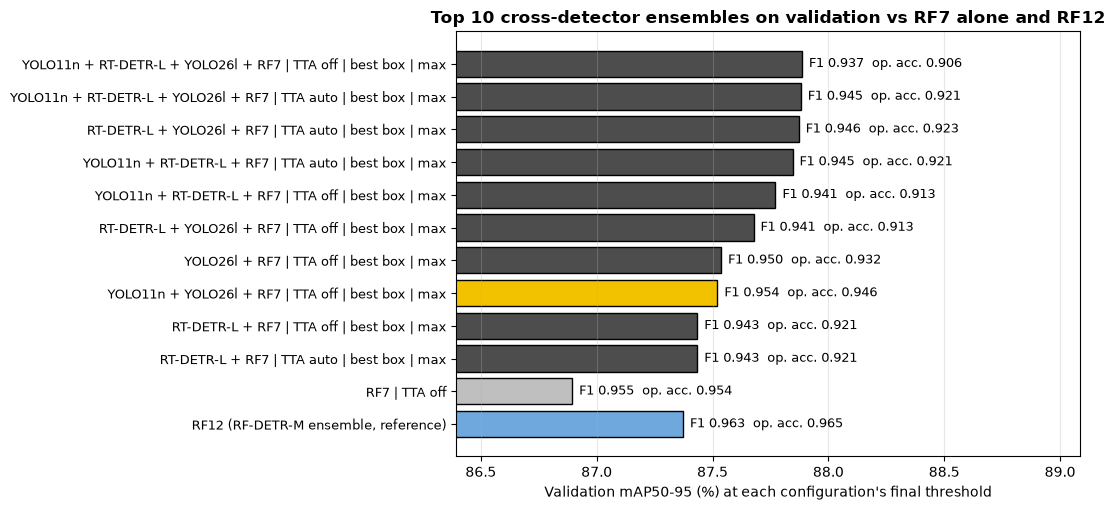

In [15]:
lab = lambda r: ('RF12 (RF-DETR-M ensemble, reference)' if r['n'] == 0 else f"{r['Detectors']} | TTA {r['TTA']}" + (f" | {r['Box']} box | {r['Score']}" if r['n'] > 1 else ''))
top = pd.concat([search[search.n > 1].head(10), RF7_ROW.to_frame().T, REF.to_frame().T]).iloc[::-1].reset_index(drop=True)
colors = ['#f2c200' if r['config'] == BEST['config'] else ('#6fa8dc' if r['n'] == 0 else ('0.75' if r['n'] == 1 else '0.3')) for _, r in top.iterrows()]
fig, ax = plt.subplots(figsize=(11, 5.2))
ax.barh(range(len(top)), top['mAP50-95'].astype(float) * 100, color=colors, edgecolor='black')
for i, r in top.iterrows():
    ax.text(float(r['mAP50-95']) * 100 + 0.03, i, f"F1 {float(r['F1']):.3f}  op. acc. {float(r['Op. acc.']):.3f}", va='center', fontsize=9)
ax.set_yticks(range(len(top))); ax.set_yticklabels([lab(r) for _, r in top.iterrows()], fontsize=9)
ax.set_xlim(float(top['mAP50-95'].min()) * 100 - 0.5, float(top['mAP50-95'].max()) * 100 + 1.2)
ax.set_xlabel("Validation mAP50-95 (%) at each configuration's final threshold"); ax.grid(axis='x', alpha=0.3)
ax.set_title('Top 10 cross-detector ensembles on validation vs RF7 alone and RF12', fontweight='bold')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'fig_search_top.png', dpi=200); plt.show()

## Section 16: Test Set (each system at its validation threshold)

In [16]:
def run_test(cfg, t):
    members, t_, box, score = cfg
    if len(members) == 1 and t_ == 'off':
        n = members[0]; preds = [filt(r['A'][n]) for r in test]; ms = MS_A[n]
    else:
        gv, _ = get_groups(members, t_, 'val'); gt_, ms = get_groups(members, t_, 'test')
        if score == 'stacking':
            mdl = make_stacker().fit(np.array([f['feats'] for g in gv for f in g]), labels_for(gv, val, box))
            scores = [mdl.predict_proba(np.stack([f['feats'] for f in g]))[:, 1] if g else np.zeros(0) for g in gt_]
        else:
            scores = [np.array([f[score] for f in g]) for g in gt_]
        preds = to_preds(gt_, box, scores)
    P = to_sv(preds)
    return {'Final t': t, **at_conf(P, TARGETS['test'], t), 'ms/image': ms}, P

results, PRED = {}, {}
for n in MODEL_NAMES:
    row = search[(search.n == 1) & (search.Detectors == n) & (search.TTA == 'off')].iloc[0]
    results[n], PRED[n] = run_test(row.config, row['Final t'])
results['RF12'], PRED['RF12'] = run_test((('RF12',), 'off', 'best', 'max'), REF['Final t'])
results['Best cross-detector ensemble'], PRED['ens'] = run_test(BEST.config, BEST['Final t'])
table = pd.DataFrame(results).T
table.to_csv(RESULTS_DIR / 'test_results.csv')
display(table[['Final t', 'mAP50', 'mAP50-95', 'Precision', 'Recall', 'F1', 'Pure acc.', 'Correct', 'Wrong', 'FP', 'Missed', 'ms/image']].round(4))

,Final t,mAP50,mAP50-95,Precision,Recall,F1,Pure acc.,Correct,Wrong,FP,Missed,ms/image
YOLO11n,0.45,0.9034,0.7262,0.9174,0.9135,0.9154,0.9886,433.0,5.0,34.0,36.0,11.5064
RT-DETR-L,0.60,0.9409,0.7507,0.9216,0.9430,0.9322,0.9978,447.0,1.0,37.0,26.0,29.7001
YOLO26l,0.50,0.9278,0.7577,0.9349,0.9388,0.9368,0.9911,445.0,4.0,27.0,25.0,16.3246
RF7,0.45,0.9707,0.8770,0.9586,0.9768,0.9676,0.9978,463.0,1.0,19.0,10.0,25.4384
RF12,0.50,0.9722,0.8725,0.9706,0.9768,0.9737,1.0000,463.0,0.0,14.0,11.0,69.6164
Best cross-detector ensemble,0.60,0.9641,0.8666,0.9094,0.9747,0.9409,0.9935,462.0,3.0,43.0,9.0,55.7210


## Section 17: Cross-Detector Ensemble vs RF12 and RF7 (Validation and Test)

In [17]:
cols = ['mAP50-95', 'Precision', 'Recall', 'F1', 'Correct', 'Wrong', 'FP', 'Missed', 'ms/image']
gain = pd.DataFrame({'Val RF7': RF7_ROW[cols], 'Val RF12': REF[cols], 'Val cross-detector ensemble': BEST[cols],
                     'Test RF7': table.loc['RF7', cols], 'Test RF12': table.loc['RF12', cols],
                     'Test cross-detector ensemble': table.loc['Best cross-detector ensemble', cols]})
gain.to_csv(RESULTS_DIR / 'ensemble_vs_rf12.csv')
display(gain.round(4))

,Val RF7,Val RF12,Val cross-detector ensemble,Test RF7,Test RF12,Test cross-detector ensemble
mAP50-95,0.868941,0.873725,0.875209,0.8770,0.8725,0.8666
Precision,0.954148,0.964835,0.946237,0.9586,0.9706,0.9094
Recall,0.956236,0.960613,0.962801,0.9768,0.9768,0.9747
F1,0.955191,0.962719,0.954447,0.9676,0.9737,0.9409
Correct,437,439,440,463.0000,463.0000,462.0000
Wrong,2,1,0,1.0000,0.0000,3.0000
FP,19,15,25,19.0000,14.0000,43.0000
Missed,18,17,17,10.0000,11.0000,9.0000
ms/image,25.438357,69.616436,56.011068,25.4384,69.6164,55.7210


## Section 18: Per-class Test Results and Threshold Sweeps

In [18]:
pcs = {}
for name in list(results):
    c, w, fp, m = counts_at(PRED[name if name in ALL_NAMES else 'ens'], TARGETS['test'], results[name]['Final t'])
    pcs[name] = pd.DataFrame({'Correct': c, 'Wrong': w, 'FP': fp, 'Missed': m}, index=CLASS_NAMES)
pc = pd.concat(pcs, axis=1); pc.to_csv(RESULTS_DIR / 'per_class_test.csv'); display(pc)

# validation threshold sweep of every single detector (TTA off), as in the run-selection tables
rows = []
for n in ALL_NAMES:
    P = to_sv([filt(r['A'][n]) for r in val])
    for t in CONFS:
        rows.append({'Detector': n, 'Conf': t, **at_conf(P, TARGETS['val'], t)})
sweeps = pd.DataFrame(rows); sweeps.to_csv(RESULTS_DIR / 'single_detector_sweeps_val.csv', index=False)
display(sweeps[sweeps.Detector == 'RF12'].round(4))

YOLO11n                  RT-DETR-L                  YOLO26l        \
         Correct Wrong  FP Missed   Correct Wrong  FP Missed Correct Wrong   
buffalo       54     0   3      5        54     0   7      6      51     0   
elephant      65     2  13     10        66     0  10      9      67     2   
rhino         40     0   2      2        43     0   0      0      41     0   
zebra         75     0   8      5        76     0  13      4      79     0   
okapi         76     0   2      5        78     0   4      4      79     0   
leopard       59     1   3      3        61     0   1      1      61     0   
cheetah       64     2   3      6        69     1   2      2      67     2   

          ... RF7           RF12                 Best cross-detector ensemble  \
          ...  FP Missed Correct Wrong FP Missed                      Correct   
buffalo   ...   1      4      57     0  0      3                           56   
elephant  ...   7      2      71     0  7      4                           73   
rhino     ...   1      0      43     0  1      0                           43   
zebra     ...  10      3      78     0  5      2                           78   
okapi     ...   0      0      82     0  0      0                           81   
leopard   ...   0      0      63     0  0      0                           62   
cheetah   ...   0      1      69     0  1      2                           69   

                           
         Wrong  FP Missed  
buffalo      0   5      3  
elephant     1  15      2  
rhino        0   1      0  
zebra        0  15      2  
okapi        0   2      0  
leopard      0   2      0  
cheetah      2   3      2  

[7 rows x 24 columns]

,Detector,Conf,Correct,Wrong,FP,Missed,Precision,Recall,F1,Op. acc.,Pure acc.,mAP50,mAP50-95
40,RF12,0.25,445,3,47,9,0.8990,0.9737,0.9349,0.8990,0.9933,0.9705,0.8826
41,RF12,0.30,444,2,42,11,0.9098,0.9716,0.9397,0.9098,0.9955,0.9678,0.8815
42,RF12,0.35,441,1,38,15,0.9188,0.9650,0.9413,0.9188,0.9977,0.9614,0.8772
43,RF12,0.40,439,1,26,17,0.9421,0.9606,0.9512,0.9421,0.9977,0.9573,0.8737
44,RF12,0.45,439,1,21,17,0.9523,0.9606,0.9564,0.9523,0.9977,0.9573,0.8737
45,RF12,0.50,439,1,15,17,0.9648,0.9606,0.9627,0.9648,0.9977,0.9573,0.8737
46,RF12,0.60,435,1,13,21,0.9688,0.9519,0.9603,0.9688,0.9977,0.9493,0.8682
47,RF12,0.70,429,1,7,27,0.9817,0.9387,0.9597,0.9817,0.9977,0.9385,0.8598
48,RF12,0.80,419,1,3,37,0.9905,0.9168,0.9523,0.9905,0.9976,0.9160,0.8458
49,RF12,0.90,389,0,1,68,0.9974,0.8512,0.9185,0.9974,1.0000,0.8500,0.7918


## Section 19: Zip Results

In [19]:
tmp = RESULTS_DIR / 'zip'; tmp.mkdir(exist_ok=True)
for f in RESULTS_DIR.glob('*'):
    if f.suffix in {'.csv', '.png'}: shutil.copy2(f, tmp / f.name)
archive = shutil.make_archive(str(RESULTS_DIR.parent / 'cross_detector_ensemble_results'), 'zip', tmp)
print('Zip:', archive, '| GPU:', GPU)

Zip: c:\Users\zheng\Documents\ISY5002-PRS-G14\ai-applications\vs_notebooks\cross_detector_ensemble_results.zip | GPU: NVIDIA GeForce RTX 3070
